# Predictive contribution, representations and selection stability

**Question:** Which families contribute beyond the remaining predictors, and do the selected representatives survive changes in the training pitchers?

All models fit the same chronological training cohort, with training-fitted medians, tail bounds, missing flags and scaling. No test outcomes enter these comparisons. L2 logistic models provide the common comparison; Elastic Net is one additional selection instrument. The target is the inherited broad elbow endpoint, not confirmed UCL injury.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/feature_consolidation.yaml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import json
import pandas as pd
from IPython.display import display,Markdown,Image
from src.injury_analysis.consolidation_common import OUT,CACHE,read_table
assert (OUT/'candidate_freeze.json').exists(), 'First run: .venv/bin/python -m src.injury_analysis.consolidation_workflow'
def plot(name):display(Image(filename=str(OUT/'figures'/f'{name}.png')))
display(read_table('cohort_counts'))
display(read_table('event_support'))

,partition,rows,positive_rows,pitchers,prevalence
0,test,27665,708,789,0.025592
1,train,81145,1441,1290,0.017758
2,validation,26796,600,783,0.022391


,partition,rows,positive_rows,represented_events,initial_explicit_ucl_events,later_supplemental_ucl_confirmation,first_appearance,last_appearance
0,test,27665,708,110,5,24,2024-03-20,2025-09-24
1,train,81145,1441,223,15,46,2015-04-14,2021-09-24
2,validation,26796,600,89,3,17,2022-04-07,2023-09-29


## Family ablation and grouped permutation

Removing a family and refitting asks whether the others can substitute for it. Shuffling a family asks whether the fitted full model relies on it. Both its measurements and missing flags are shuffled together within season and role (season only when testing role). This is marginal permutation within strata, not full conditional importance.

Ablation intervals resample whole validation pitchers 300 times. Permutation bars show variation over five shuffles, **not confidence intervals**. Multiple comparisons, model dependence and only 89 represented validation injury events limit uniqueness claims. Event warning uses 7–30-day lead time and 5% of eligible rows; its denominator includes all 120 qualifying events, even events without an observable warning opportunity.

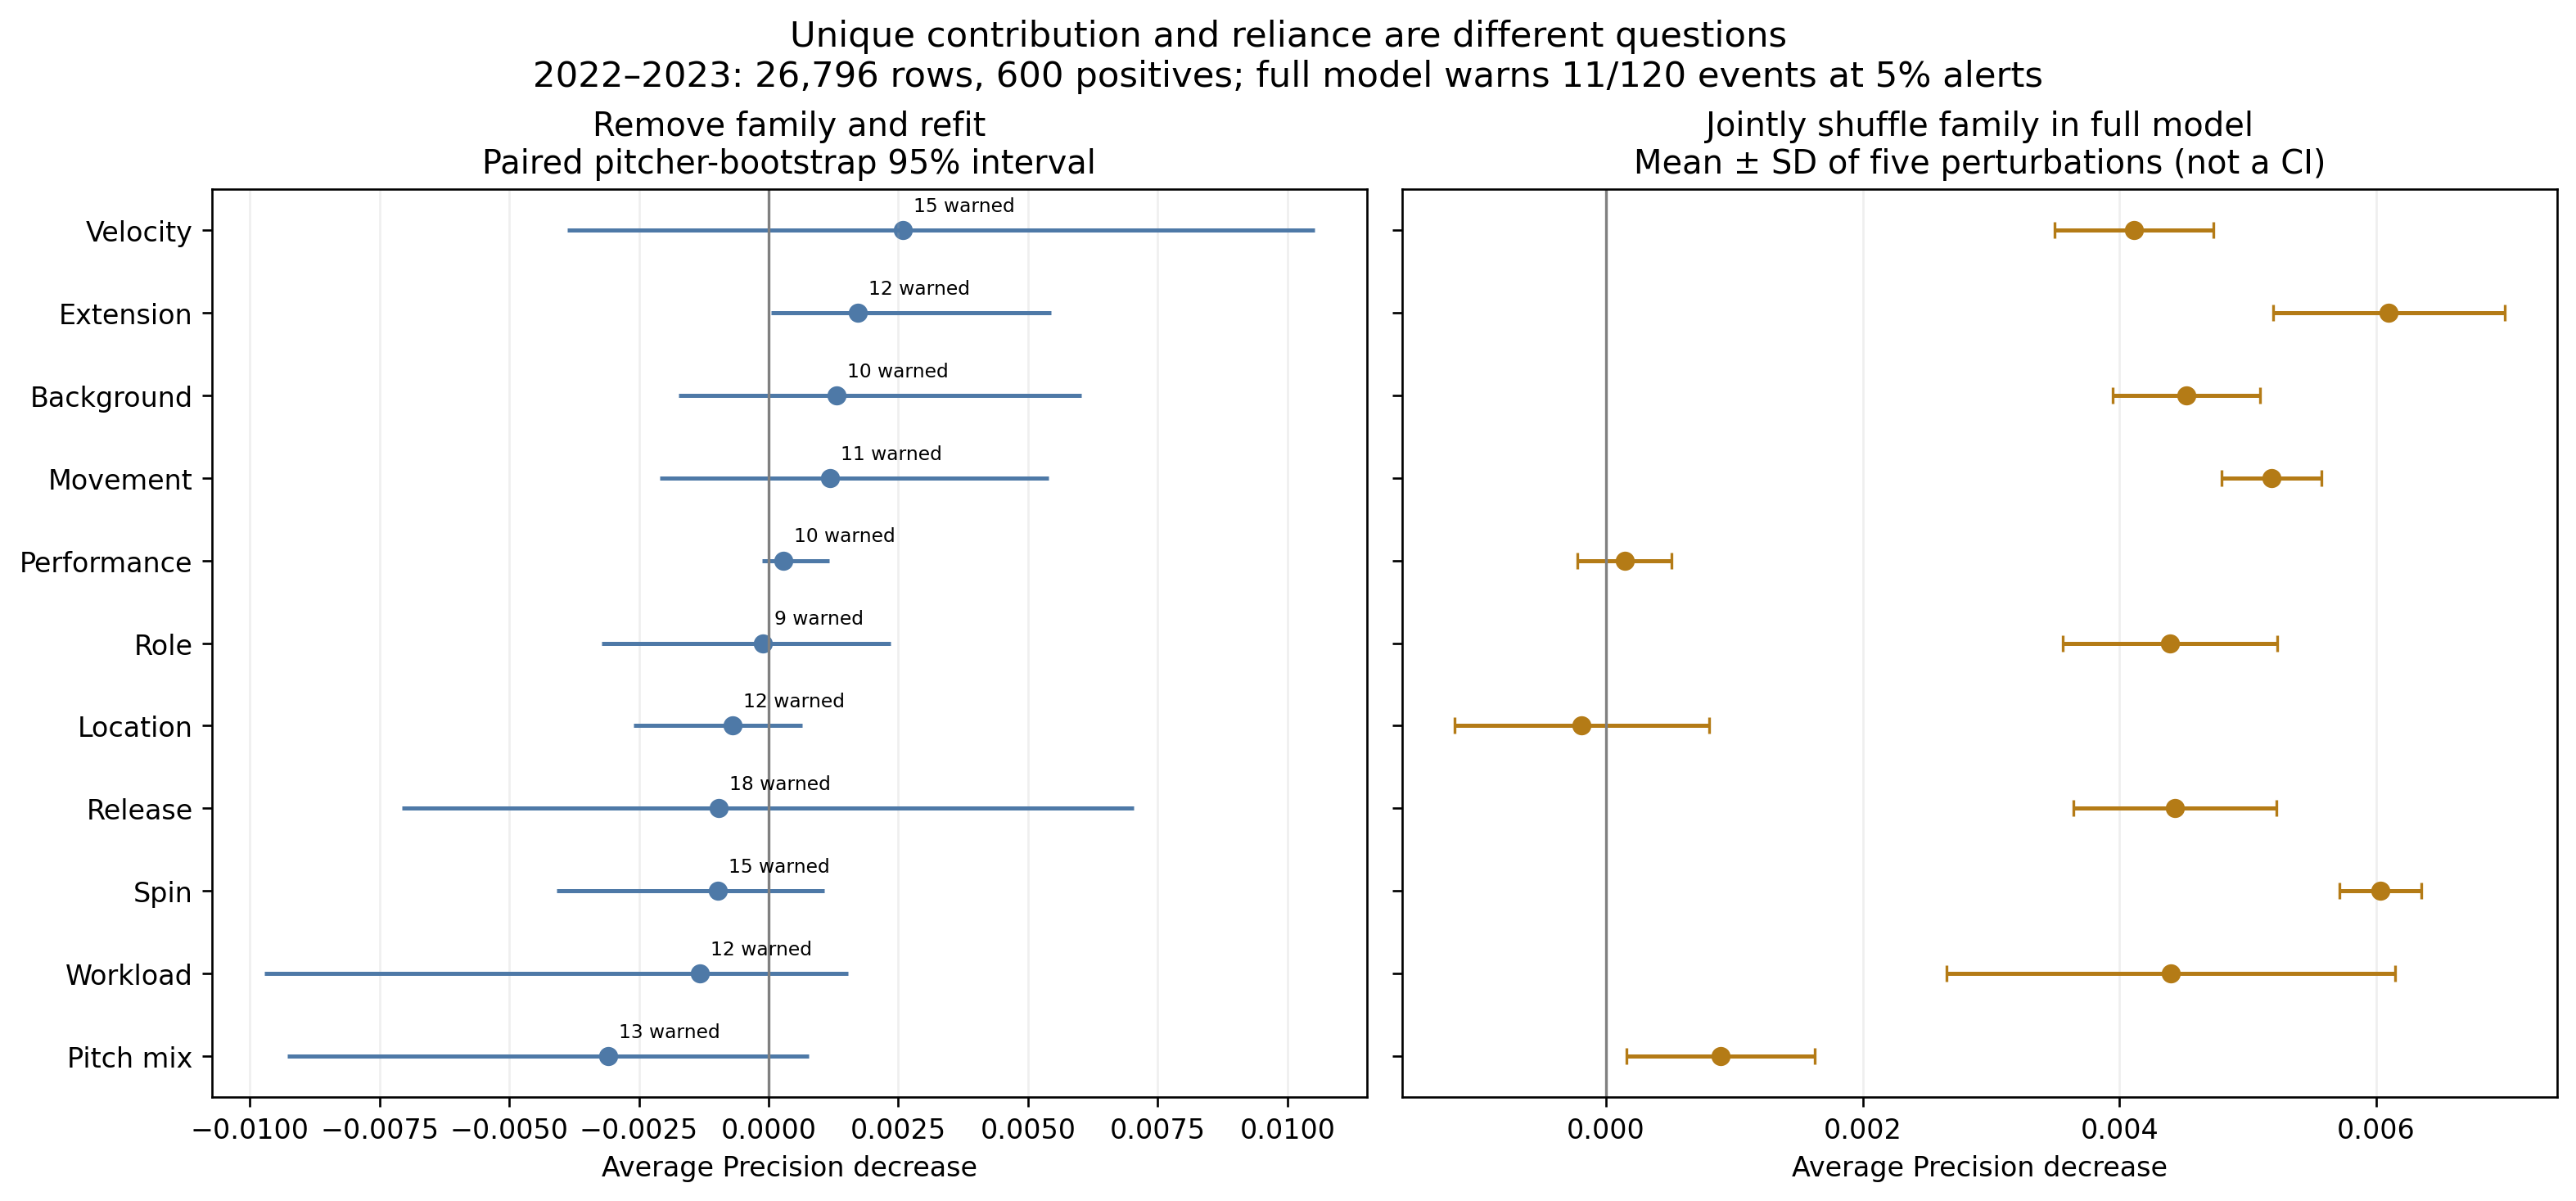

,variant,family,features,average_precision,pr_lift,brier_score,alerted_events,injury_event_recall,median_warning_lead_days,non_actionable_alerts_per_pitcher_season
0,Full feasible,NaN,333,0.030615,1.367247,0.022515,11,0.091667,21.0,1.079339
1,Correlation representatives,NaN,189,0.024911,1.112517,0.022385,10,0.083333,13.5,1.091736
2,Previous 62 (same preprocessing),NaN,62,0.028366,1.266822,0.022004,13,0.108333,18.0,1.088430
3,Full plus support,NaN,353,0.031006,1.384741,0.022239,10,0.083333,20.5,1.080165
4,Support only,NaN,20,0.024341,1.087049,0.021971,8,0.066667,23.5,1.084298
5,Without family 00,Velocity,296,0.028032,1.251907,0.022349,15,0.125000,19.0,1.078512
6,Only family 00,Velocity,37,0.030963,1.382827,0.021943,13,0.108333,28.0,1.078512
7,Without family 01,Release position and variability,263,0.031583,1.410476,0.022243,18,0.150000,19.5,1.071074
8,Only family 01,Release position and variability,70,0.022601,1.009348,0.022055,7,0.058333,19.0,1.086777
9,Without family 02,Extension,306,0.028899,1.290635,0.022555,12,0.100000,21.0,1.076860


In [2]:
plot('03_family_ablation_and_permutation')
display(read_table('family_performance')[['variant','family','features','average_precision','pr_lift',
 'brier_score','alerted_events','injury_event_recall','median_warning_lead_days','non_actionable_alerts_per_pitcher_season']])

## Different representations of the same concept

Small nested comparisons share age, hand, prior IL history, role and workload context. They add baseline, departure, prior slope, recent level and current level in the declared order. These contrasts are order-dependent, not exhaustive searches or independent hypothesis tests. Inspect their intervals and warning counts together.

Arm angle and within-outing velocity decline lack long-history measurement support. Separate common-row modern and starter sensitivities prevent interpreting historical missingness as proof of no signal.

In [3]:
display(read_table('representation_comparisons')[['concept','step','addition','added_features','features',
 'average_precision','ap_increment','increment_low','increment_high','alerted_events']])
display(read_table('supported_cohort_sensitivity'))

,concept,step,addition,added_features,features,average_precision,ap_increment,increment_low,increment_high,alerted_events
0,Velocity,0,Shared context,NaN,7,0.026648,0.000000,0.000000,0.000000,19
1,Velocity,1,Prior baseline,avg_fb_velo_baseline_mean,8,0.027207,0.000559,-0.001292,0.002527,20
2,Velocity,2,Departure,velo_z,9,0.028000,0.000793,-0.001621,0.003712,20
3,Velocity,3,Prior slope,fb_velo_slope_prev_5,10,0.028078,0.000078,-0.000226,0.000548,19
4,Velocity,4,Recent level,avg_fb_velo_prev_5,11,0.028797,0.000719,-0.000417,0.002963,18
5,Velocity,5,Current level,avg_fb_velo,12,0.028795,-0.000002,-0.000009,0.000004,18
6,Velocity,6,Velocity variability,fb_velo_sd,13,0.028684,-0.000111,-0.002271,0.001618,18
7,Release position,0,Shared context,NaN,7,0.026648,0.000000,0.000000,0.000000,19
8,Release position,1,Prior baseline,release_x_avg_baseline_mean;release_z_avg_base...,9,0.025277,-0.001371,-0.005269,0.002743,16
9,Release position,2,Departure,release_x_z;release_z_z,11,0.025127,-0.000150,-0.000724,0.000370,16


,analysis,variant,status,train_events,validation_events,rows,positive_rows,represented_events,prevalence,average_precision,...,observable_events,alerted_events,injury_event_recall,median_warning_lead_days,false_alerts_per_pitcher_season,non_actionable_alerts_per_pitcher_season,precision,recall,ap_increment_low,ap_increment_high
0,Modern arm angle,Base,fit,38,89,26453,590,89,0.022304,0.022051,...,80,11,0.091667,17.0,1.080901,1.087573,0.019667,0.044068,NaN,NaN
1,Modern arm angle,Base plus supported measurements,fit,38,89,26453,590,89,0.022304,0.021153,...,80,10,0.083333,24.5,1.085905,1.088407,0.015129,0.033898,-0.003045,0.000723
2,Starter within-outing velocity,Base,fit,82,22,4566,65,22,0.014236,0.021366,...,21,5,0.041667,26.0,0.504608,0.506912,0.039474,0.138462,NaN,NaN
3,Starter within-outing velocity,Base plus supported measurements,fit,82,22,4566,65,22,0.014236,0.021231,...,21,4,0.033333,19.5,0.509217,0.511521,0.030702,0.107692,-0.002908,0.003104


## Sparse selection and whole-pitcher stability

Six Elastic Net settings span three regularization strengths and two mixing parameters, selected by validation AP. All 333 feasible substantive fields enter screening, preserving alternatives for weight exchange. Rare binary fields and missing flags remain on raw unit scale for the sparse model; continuous fields are standardized. This penalty geometry differs from the common L2 comparisons and is disclosed rather than interpreted as a controlled algorithm contest.

Sixteen refits resample entire training pitchers, holding the chosen hyperparameters fixed. Measured-value selection, missing-flag selection, sign, rank and marginal permutation stability remain separate. With only 16 refits, frequencies change in steps of 6.25%; this is a stability diagnostic, not formal false-discovery-controlled stability selection. Validation-bootstrap intervals condition on fitted models and do not incorporate the full tuning search.

,model,C,l1_ratio,input_features,nonzero_features,nonzero_with_flags,rows,positive_rows,represented_events,prevalence,...,calibration_bias,qualifying_events,observable_events,alerted_events,injury_event_recall,median_warning_lead_days,false_alerts_per_pitcher_season,non_actionable_alerts_per_pitcher_season,precision,recall
0,elastic_C0.003_mix0.25,0.003,0.25,333,71,71,26796,600,89,0.022391,...,-0.003865,120,80,11,0.091667,13.0,1.080992,1.090083,0.023152,0.051667
1,elastic_C0.003_mix0.75,0.003,0.75,333,4,4,26796,600,89,0.022391,...,-0.004675,120,80,18,0.150000,15.0,1.068595,1.086777,0.034354,0.076667
2,elastic_C0.03_mix0.25,0.030,0.25,333,213,222,26796,600,89,0.022391,...,-0.003082,120,80,12,0.100000,20.0,1.065289,1.080992,0.037341,0.083333
3,elastic_C0.03_mix0.75,0.030,0.75,333,142,146,26796,600,89,0.022391,...,-0.003625,120,80,16,0.133333,17.5,1.062810,1.076860,0.039582,0.088333
4,elastic_C0.3_mix0.25,0.300,0.25,333,304,309,26796,600,89,0.022391,...,-0.002181,120,80,12,0.100000,20.0,1.066942,1.080992,0.035848,0.080000
5,elastic_C0.3_mix0.75,0.300,0.75,333,260,267,26796,600,89,0.022391,...,-0.002228,120,80,12,0.100000,20.0,1.067769,1.080992,0.035101,0.078333


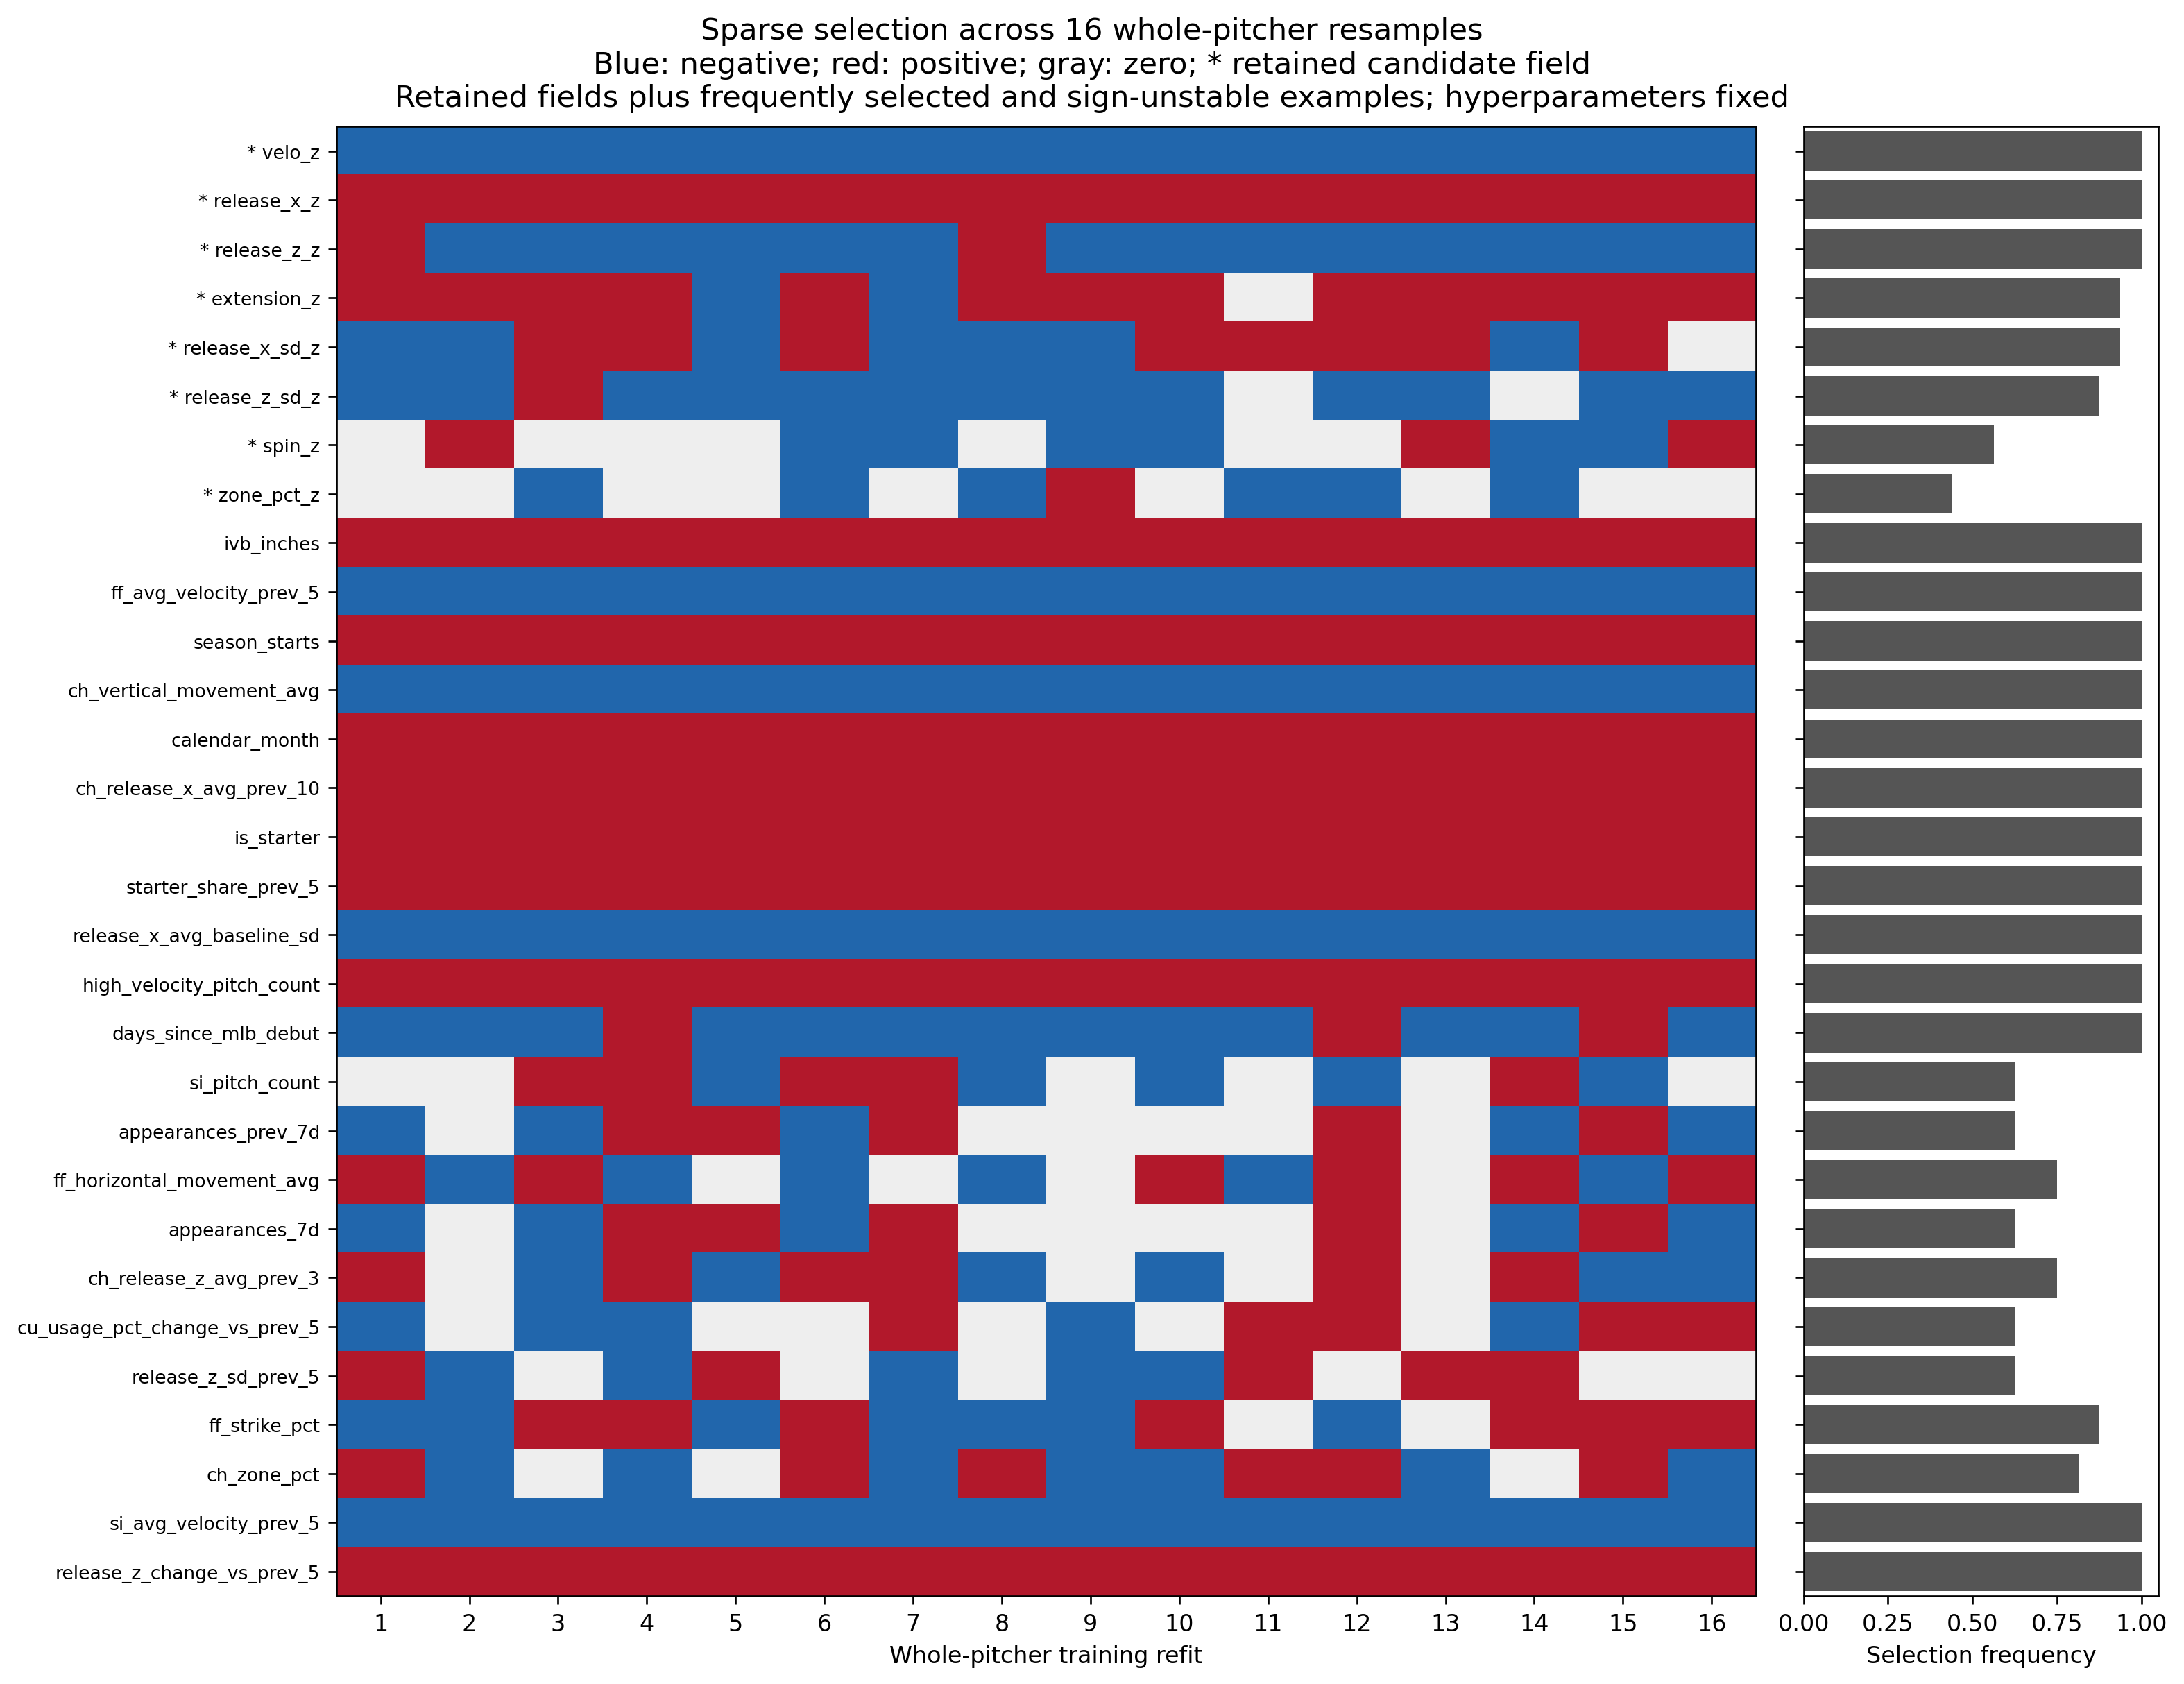

,feature,selection_frequency,selection_with_indicator_frequency,top_rank_frequency,positive_frequency,negative_frequency,mean_coefficient,coefficient_sd,mean_rank,rank_sd,median_absolute_coefficient,mean_absolute_indicator_coefficient,conditional_sign_stability,permutation_mean,permutation_sd,permutation_positive_frequency
0,ivb_inches,1.0000,1.0000,0.9375,1.0000,0.0000,0.309604,0.084934,10.93750,10.188024,0.316853,0.061227,1.0,2.971537e-03,3.925668e-03,0.9375
1,ff_avg_velocity_prev_5,1.0000,1.0000,0.8750,0.0000,1.0000,-0.305480,0.143146,19.25000,27.211517,0.296908,0.002163,1.0,3.585515e-03,6.112720e-03,1.0000
2,season_starts,1.0000,1.0000,0.8750,1.0000,0.0000,0.274783,0.111716,20.93750,27.287283,0.288358,0.019733,1.0,8.274193e-05,6.351078e-04,0.4375
3,ch_vertical_movement_avg,1.0000,1.0000,0.8125,0.0000,1.0000,-0.269902,0.088446,17.62500,18.322573,0.280350,0.007166,1.0,1.108235e-03,9.762264e-04,0.9375
4,calendar_month,1.0000,1.0000,0.7500,1.0000,0.0000,0.235262,0.079388,24.00000,24.859606,0.240498,0.000000,1.0,3.298745e-03,3.190092e-03,1.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328,ch_usage_pct_prev_5,0.0625,0.0625,0.0000,0.0625,0.0000,0.006531,0.026125,268.93750,50.288791,0.000000,0.000000,1.0,-4.087713e-06,1.635085e-05,0.0000
329,location_variability,0.0625,0.0625,0.0000,0.0000,0.0625,-0.000615,0.002460,277.12500,17.595928,0.000000,0.000000,1.0,-1.144607e-07,4.578427e-07,0.0000
330,pitch_count,0.0625,0.0625,0.0000,0.0625,0.0000,0.000863,0.003453,276.40625,20.664155,0.000000,0.000000,1.0,-1.421121e-06,5.684484e-06,0.0000
331,total_pitches,0.0625,0.0625,0.0000,0.0625,0.0000,0.000863,0.003453,276.40625,20.664155,0.000000,0.000000,1.0,-1.421121e-06,5.684484e-06,0.0000


,correlation_cluster,signal_interpretation,cluster_selection_frequency
0,Appearance performance__001,Current state,1.0000
1,Appearance performance__002,Current state,1.0000
2,Appearance performance__003,Current state,0.6875
3,Appearance performance__004,Current state,0.8750
4,Appearance performance__005,Current state,0.5625
...,...,...,...
184,Workload and rest__013,Workload,0.8125
185,Workload and rest__014,Workload,0.9375
186,Workload and rest__015,Workload,0.9375
187,Workload and rest__016,Profile/history,0.8750


,repeat,unique_training_pitchers,distinct_positive_training_events,train_rows,rows,positive_rows,represented_events,prevalence,average_precision,roc_auc,...,calibration_bias,qualifying_events,observable_events,alerted_events,injury_event_recall,median_warning_lead_days,false_alerts_per_pitcher_season,non_actionable_alerts_per_pitcher_season,precision,recall
0,0,814,134,80098,26796,600,89,0.022391,0.030047,0.543228,...,0.001431,120,80,10,0.083333,27.0,1.055372,1.071074,0.046303,0.103333
1,1,812,146,77371,26796,600,89,0.022391,0.039631,0.531873,...,0.002522,120,80,13,0.108333,18.0,1.057851,1.071901,0.044063,0.098333
2,2,806,131,78453,26796,600,89,0.022391,0.035902,0.545468,...,-0.007889,120,80,18,0.150000,18.0,1.054545,1.073554,0.047050,0.105000
3,3,806,140,77496,26796,600,89,0.022391,0.026456,0.557828,...,0.004591,120,80,9,0.075000,27.0,1.079339,1.085124,0.024645,0.055000
4,4,811,133,80018,26796,600,89,0.022391,0.028744,0.521410,...,0.000860,120,80,13,0.108333,17.0,1.053719,1.068595,0.047797,0.106667
5,5,834,149,79128,26796,600,89,0.022391,0.028080,0.532318,...,-0.004801,120,80,13,0.108333,16.0,1.058678,1.075207,0.043316,0.096667
6,6,831,166,83923,26796,600,89,0.022391,0.029844,0.556782,...,-0.003348,120,80,14,0.116667,18.0,1.063636,1.079339,0.038835,0.086667
7,7,826,132,77942,26796,600,89,0.022391,0.027887,0.562758,...,-0.002521,120,80,11,0.091667,18.0,1.071901,1.085950,0.031367,0.070000
8,8,796,134,80781,26796,600,89,0.022391,0.025852,0.528283,...,-0.006196,120,80,10,0.083333,17.5,1.068595,1.081818,0.034354,0.076667
9,9,815,143,82314,26796,600,89,0.022391,0.028938,0.534806,...,-0.004595,120,80,11,0.091667,17.0,1.072727,1.084298,0.030620,0.068333


In [4]:
display(read_table('elastic_net_tuning'))
plot('04_selection_and_sign_stability')
display(read_table('feature_stability'))
display(read_table('cluster_selection_frequency'))
display(read_table('training_refit_performance'))

**Interpretation:** A repeatably nonzero coefficient can still have weak incremental validation value. Correlated alternatives can exchange signs or ranks; high selection frequency alone is insufficient. The final stage combines stability, temporal roles, validation ranking, warning utility and compactness.